# 06 - Composições mensais Sentinel-1 (10 m)

| | |
|---|---|
| **Tarefa do plano** | S1-08 - composições mensais Sentinel-1 2014-2026, órbita fixa + contagem de observações |
| **Variáveis (Parte I)** | #17 VV, #18 VH, #21 ângulo de incidência, #22 direção da órbita (#19 rácio e #20 delta-VV são derivados na semana 2) |
| **Fonte** | Copernicus Sentinel-1 GRD (IW) via Earth Engine `COPERNICUS/S1_GRD` |
| **Saída** | `data/raw/radar/sentinel1/<ano>/` |

Receita (`ete.datasets.sentinel1_builder`): modo IW, cenas VV+VH de **uma só**
direção de órbita, mediana mensal da retrodifusão em dB, ângulo de incidência
médio e `n_obs`. Bandas: `VV, VH, angle, n_obs`. São esperadas menos passagens em
2022-2025 (perda do Sentinel-1B); a banda `n_obs` mostra isso.

Correr primeiro `00_setup_and_authentication` e `01_study_area_aoi`. Todos os
downloads podem ser retomados: os ficheiros que já existem são saltados, e cada
ficheiro fica registado em `data/metadata/download_manifest.csv`.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "config.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))

import ee
import pandas as pd
import matplotlib.pyplot as plt

from ete import config, datasets, gee, series
from ete import grid as G

cfg = config.load_config()
gee.init(cfg)

aoi = G.load_aoi(cfg)                       # AOI das imagens (EPSG:4326)
region = gee.ee_geometry(aoi)
grid30 = G.load_grid(cfg)                   # grelha do projeto a 30 m (EPSG:32736)
grid10 = G.load_grid(cfg, 10)               # grelha a 10 m, encaixada na de 30 m
climate_bounds = tuple(G.load_aoi(cfg, "aoi_climate").total_bounds)   # O, S, E, N
MASK = gee.ee_geometry(G.imagery_mask(cfg))  # distrito + margem: fora daqui as imagens mensais ficam sem dados

*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


## Escolher a direção da órbita

Cenas por direção de órbita e por ano sobre a AOI. Com `orbit_pass: auto` usa-se
a direção com mais cenas em todo o período; escrever a escolha em
`config/config.yaml` assim que a equipa concordar, para que nunca mude entre
execuções.

In [2]:
s1 = datasets.sentinel1_collection(cfg, region)
passes = s1.aggregate_histogram("orbitProperties_pass").getInfo()
print("cenas por direção de órbita:", passes)

per_year = s1.map(lambda i: i.set("key", ee.String(i.get("orbitProperties_pass")).cat("_").cat(i.date().format("YYYY"))))
counts = pd.Series(per_year.aggregate_histogram("key").getInfo())
counts.index = pd.MultiIndex.from_tuples([k.split("_") for k in counts.index], names=["pass", "year"])
counts.unstack("pass").fillna(0).astype(int)

cenas por direção de órbita: {'ASCENDING': 1034, 'DESCENDING': 940}


pass,ASCENDING,DESCENDING
year,,
2015,48,3
2016,95,0
2017,92,66
2018,92,86
2019,93,149
2020,89,127
2021,90,120
2022,91,60
2023,91,59


## Parâmetros

**Formato dos ficheiros.** Os valores são guardados como inteiros (`DTYPE`), multiplicados
por `SCALE`, para ocupar menos disco e menos internet sem perda relevante de precisão.
O fator fica gravado dentro do GeoTIFF: ler sempre com `series.read_scaled(ficheiro)`,
que devolve os valores físicos. As bandas `n_obs` e `label_mode` não são multiplicadas.
Com `MASK`, os píxeis fora do distrito + margem ficam sem dados (-9999).

In [3]:
ds = cfg["datasets"]["sentinel1"]
ORBIT_PASS = ds["orbit_pass"]
if ORBIT_PASS == "auto":
    ORBIT_PASS = max(passes, key=passes.get)
print("direção da órbita usada:", ORBIT_PASS)

DATASET, SOURCE_ID = "sentinel1", ds["id"]
BANDS = ds["bands"] + ["n_obs"]
GRID, DTYPE, START = grid10, "int16", ds["start"]
SCALE = 100                                 # dB e ângulo guardados como inteiro (x100 = 0,01 dB)
OUT_DIR = config.path(cfg, "sentinel1")
builder = datasets.sentinel1_builder(cfg, region, ORBIT_PASS)

direção da órbita usada: ASCENDING


## Teste com um mês

Correr sempre um mês primeiro e observá-lo antes de lançar o período completo.
`2023-02` está na época chuvosa, quando as nuvens e as cheias são mais prováveis.

In [4]:
TEST_MONTH = "2023-02"
test = gee.download_monthly(cfg, DATASET, SOURCE_ID, builder, BANDS, GRID, OUT_DIR,
                            start=f"{TEST_MONTH}-01", end=f"{TEST_MONTH}-28", dtype=DTYPE, scale=SCALE, mask=MASK)
test

sentinel1:   0%|          | 0/1 [00:00<?, ?it/s]

,period,status,file,n_images,orbit_pass,relative_orbits
0,2023-02,downloaded,sentinel1_marracuene_2023-02_10m.tif,7,ASCENDING,"{'145.0': 4, '72.0': 3}"


<Axes: title={'center': 'sentinel1_marracuene_2023-02_10m.tif\nn_obs'}>

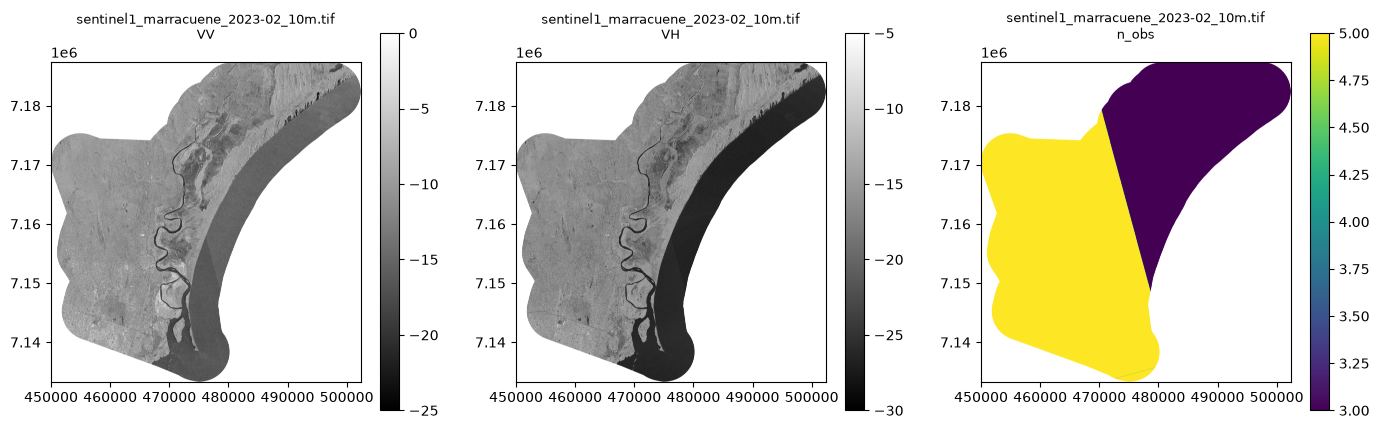

In [5]:
test_file = next(OUT_DIR.rglob(f"*_{TEST_MONTH}_*.tif"))
fig, axes = plt.subplots(1, 3, figsize=(17, 7))
series.show_raster(test_file, band="VV", ax=axes[0], cmap="gray", vmin=-25, vmax=0)
series.show_raster(test_file, band="VH", ax=axes[1], cmap="gray", vmin=-30, vmax=-5)
series.show_raster(test_file, band="n_obs", ax=axes[2], cmap="viridis")

## Período completo

Demora bastante (horas para os datasets de 10 m). Pode ser interrompido e
retomado a qualquer momento; os meses já concluídos são saltados.

In [4]:
log = gee.download_monthly(cfg, DATASET, SOURCE_ID, builder, BANDS, GRID, OUT_DIR, start=START, dtype=DTYPE, scale=SCALE, mask=MASK)
log["status"].value_counts()

sentinel1:   0%|          | 0/144 [00:00<?, ?it/s]

status
exists        88
downloaded    49
absent         7
Name: count, dtype: int64

## Inventário

In [5]:
inv = series.monthly_inventory(OUT_DIR)
expected = [m.strftime("%Y-%m") for m in gee.month_starts(START, config.period_end(cfg))]
missing = sorted(set(expected) - set(inv["period"]))
print(f"{len(inv)} ficheiros, {inv['size_mb'].sum() / 1e3:.2f} GB em disco")
print(f"{len(missing)} de {len(expected)} meses sem ficheiro (ausentes na fonte ou com falha):")
print(missing)

137 ficheiros, 7.19 GB em disco
7 de 144 meses sem ficheiro (ausentes na fonte ou com falha):
['2014-10', '2014-11', '2014-12', '2015-01', '2015-02', '2015-03', '2015-10']
